In [1]:
import numpy as np
print(np.__version__)

2.5.5


In [2]:
import pandas as pd
print(pd.__version__)

3.1.1


In [5]:
import matplotlib
import matplotlib.pyplot as plt
print(matplotlib.__version__)

3.11.2


In [7]:
DF = pd.read_csv("energy.csv")
print(DF)

          date  temperature_c  usage_kwh  household_size
0   2026-11-01             14         18               2
1   2026-11-02             12         21               2
2   2026-11-03             15         17               3
3   2026-11-04             10         25               3
4   2026-11-05              8         29               2
5   2026-11-06              9         27               4
6   2026-11-07             11         24               3
7   2026-11-08             16         16               2
8   2026-11-09             18         15               3
9   2026-11-10              7         32               4
10  2026-11-11             13         20               2
11  2026-11-12              6         35               4


In [8]:
df = DF.copy()

In [9]:
print(df)

          date  temperature_c  usage_kwh  household_size
0   2026-11-01             14         18               2
1   2026-11-02             12         21               2
2   2026-11-03             15         17               3
3   2026-11-04             10         25               3
4   2026-11-05              8         29               2
5   2026-11-06              9         27               4
6   2026-11-07             11         24               3
7   2026-11-08             16         16               2
8   2026-11-09             18         15               3
9   2026-11-10              7         32               4
10  2026-11-11             13         20               2
11  2026-11-12              6         35               4


In [10]:
print(df.head(10))


         date  temperature_c  usage_kwh  household_size
0  2026-11-01             14         18               2
1  2026-11-02             12         21               2
2  2026-11-03             15         17               3
3  2026-11-04             10         25               3
4  2026-11-05              8         29               2
5  2026-11-06              9         27               4
6  2026-11-07             11         24               3
7  2026-11-08             16         16               2
8  2026-11-09             18         15               3
9  2026-11-10              7         32               4


In [11]:
print(df.isnull().sum())

date              0
temperature_c     0
usage_kwh         0
household_size    0
dtype: int64


In [12]:
print(df.shape)

(12, 4)


In [13]:
print(df.describe())

       temperature_c  usage_kwh  household_size
count      12.000000   12.00000       12.000000
mean       11.583333   23.25000        2.833333
std         3.752777    6.52443        0.834847
min         6.000000   15.00000        2.000000
25%         8.750000   17.75000        2.000000
50%        11.500000   22.50000        3.000000
75%        14.250000   27.50000        3.250000
max        18.000000   35.00000        4.000000


In [14]:
print(df.dtypes)

date                str
temperature_c     int64
usage_kwh         int64
household_size    int64
dtype: object


In [15]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   date            12 non-null     str  
 1   temperature_c   12 non-null     int64
 2   usage_kwh       12 non-null     int64
 3   household_size  12 non-null     int64
dtypes: int64(3), str(1)
memory usage: 516.0 bytes
None


In [16]:
df["date"] = pd.to_datetime(df["date"])
print(df)

         date  temperature_c  usage_kwh  household_size
0  2026-11-01             14         18               2
1  2026-11-02             12         21               2
2  2026-11-03             15         17               3
3  2026-11-04             10         25               3
4  2026-11-05              8         29               2
5  2026-11-06              9         27               4
6  2026-11-07             11         24               3
7  2026-11-08             16         16               2
8  2026-11-09             18         15               3
9  2026-11-10              7         32               4
10 2026-11-11             13         20               2
11 2026-11-12              6         35               4


In [18]:
df["week_day"] = df["date"].dt.day_of_week
print(df)

         date  temperature_c  usage_kwh  household_size  week_day
0  2026-11-01             14         18               2         6
1  2026-11-02             12         21               2         0
2  2026-11-03             15         17               3         1
3  2026-11-04             10         25               3         2
4  2026-11-05              8         29               2         3
5  2026-11-06              9         27               4         4
6  2026-11-07             11         24               3         5
7  2026-11-08             16         16               2         6
8  2026-11-09             18         15               3         0
9  2026-11-10              7         32               4         1
10 2026-11-11             13         20               2         2
11 2026-11-12              6         35               4         3


In [19]:
df["cost_rs"] = df["usage_kwh"]*30
print(df)

         date  temperature_c  usage_kwh  household_size  week_day  cost_rs
0  2026-11-01             14         18               2         6      540
1  2026-11-02             12         21               2         0      630
2  2026-11-03             15         17               3         1      510
3  2026-11-04             10         25               3         2      750
4  2026-11-05              8         29               2         3      870
5  2026-11-06              9         27               4         4      810
6  2026-11-07             11         24               3         5      720
7  2026-11-08             16         16               2         6      480
8  2026-11-09             18         15               3         0      450
9  2026-11-10              7         32               4         1      960
10 2026-11-11             13         20               2         2      600
11 2026-11-12              6         35               4         3     1050


In [23]:
flt = df[df["temperature_c"] < 10]
avg_consumption = flt["temperature_c"].mean()
print("Average consumption of days below 10 centigrade: ",avg_consumption)

Average consumption of days below 10 centigrade:  7.5


In [24]:
temp_array = df["temperature_c"].to_numpy()
print(temp_array)

[14 12 15 10  8  9 11 16 18  7 13  6]


In [31]:
usage_array = df["usage_kwh"].to_numpy()
correlation = np.corrcoef(temp_array , usage_array)
print(correlation)

[[ 1.         -0.97927463]
 [-0.97927463  1.        ]]


In [26]:
per_day_summary = df.groupby(by="week_day").agg(
    avg_usage = ("usage_kwh" , "mean"),
    total_consumption = ("usage_kwh" , "sum")
)
print(per_day_summary)
                 

          avg_usage  total_consumption
week_day                              
0              18.0                 36
1              24.5                 49
2              22.5                 45
3              32.0                 64
4              27.0                 27
5              24.0                 24
6              17.0                 34


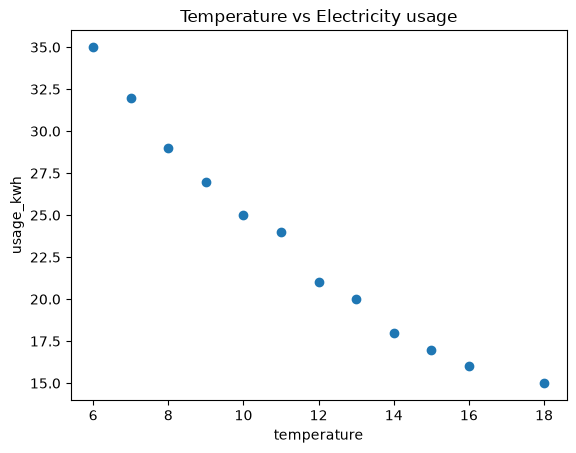

In [29]:
plt.scatter(df["temperature_c"] , df["usage_kwh"])
plt.xlabel("temperature")
plt.ylabel("usage_kwh")
plt.title("Temperature vs Electricity usage")
plt.show()
